# **Stock Tickers by Sector Excess Return Analysis**


This analysis will be taking the last ten years of the top 100 stocks in the S&P 500 and seeing if we can find any patterns within the industry and historical excess returns. 

To first get the data we will be using yfinance import so that we can collect the tickers we need. We will use a dictionary with all the sectors to do so.

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np

tickers_by_sector = {
    "Information Technology": [
        "AAPL","MSFT","NVDA","AVGO","AMD","ORCL","CRM","TXN","QCOM","MU"
    ],
    "Financials": [
        "JPM","BAC","WFC","GS","MS","BLK","AXP","CB","PGR"
    ],
    "Health Care": [
        "LLY","UNH","JNJ","ABBV","MRK","TMO","ABT","AMGN","GILD"
    ],
    "Consumer Discretionary": [
        "AMZN","TSLA","HD","MCD","NKE","LOW","SBUX","TJX","GM"
    ],
    "Communication Services": [
        "GOOGL","META","NFLX","DIS","CMCSA","T","VZ","TMUS","EA"
    ],
    "Industrials": [
        "CAT","HON","UNP","UPS","BA","RTX","DE","LMT","GE"
    ],
    "Consumer Staples": [
        "PG","KO","PEP","COST","WMT","PM","MO","CL","KMB"
    ],
    "Energy": [
        "XOM","CVX","COP","EOG","SLB","MPC","PSX","VLO","OXY"
    ],
    "Utilities": [
        "NEE","DUK","SO","D","AEP","EXC","XEL","SRE","PEG"
    ],
    "Real Estate": [
        "PLD","AMT","EQIX","CCI","SPG","O","PSA","WELL","AVB"
    ],
    "Materials": [
        "LIN","APD","SHW","FCX","NEM","NUE","VMC","MLM","ALB"
    ],
}

tickers_all = []
sector_map = {}
for sector in tickers_by_sector:
  for ticker in tickers_by_sector[sector]:
    sector_map[ticker] = sector
    tickers_all.append(ticker)

print(f"Data: {len(tickers_all)} tickers across {len(tickers_by_sector)} sectors")

date_start = "2016-05-01"
date_end = "2026-05-01"

raw = yf.download(tickers_all, start=date_start, end=date_end, auto_adjust=True)["Close"]
clean_raw = raw.ffill().bfill()
raw = clean_raw
print(f"Raw shape: {raw.shape}")


Data: 100 tickers across 11 sectors


[*********************100%***********************]  100 of 100 completed

Raw shape: (2514, 100)


Now that we got the raw closing prices, we have to turn it into Log(P_t/P_t-1) for the returns daily. After we will retrieve the T-bill returns for daily and subtract it from the previous matrix to turn our matrix into X.

In [3]:
log_returns = np.log(raw / raw.shift(1)).dropna()
print(f"Log returns shape: {log_returns.shape}")

tbill_raw = yf.download("^IRX", start=date_start, end=date_end, auto_adjust=True)["Close"]
tbill_raw = tbill_raw.ffill().dropna()

# Convert to daily log return
rf_daily = np.log(1 + tbill_raw / 100) / 252
rf_daily = rf_daily.squeeze()
rf_daily.name = "rf"

print(rf_daily.shape)

aligned = log_returns.join(rf_daily, how="inner")
rf_series = aligned["rf"]
stock_returns = aligned.drop(columns="rf")

# Subtract rf from each stock
excess_returns = stock_returns.subtract(rf_series, axis=0)

X = excess_returns.T.values
tickers_final = list(excess_returns.columns)
sectors_final = [sector_map[t] for t in tickers_final]
dates = excess_returns.index

print(f"X shape: {X.shape}")


Log returns shape: (2513, 100)


[*********************100%***********************]  1 of 1 completed

(2513,)
X shape: (100, 2512)


Now that we have the matrix X that is a $n × t $ matrix, let us continue to use linear algebra to get the SVD

In [4]:
U, s, Vt = np.linalg.svd(X, full_matrices=False)

var_explained = (s[:3]**2).sum() / (s**2).sum()
print(f"Variance explained by first 3 components: {var_explained*100:.2f}%")


Variance explained by first 3 components: 49.21%


## Principal Components Over Time

Now that we have the first 3 components we will plot them to see the variance in excess returns.

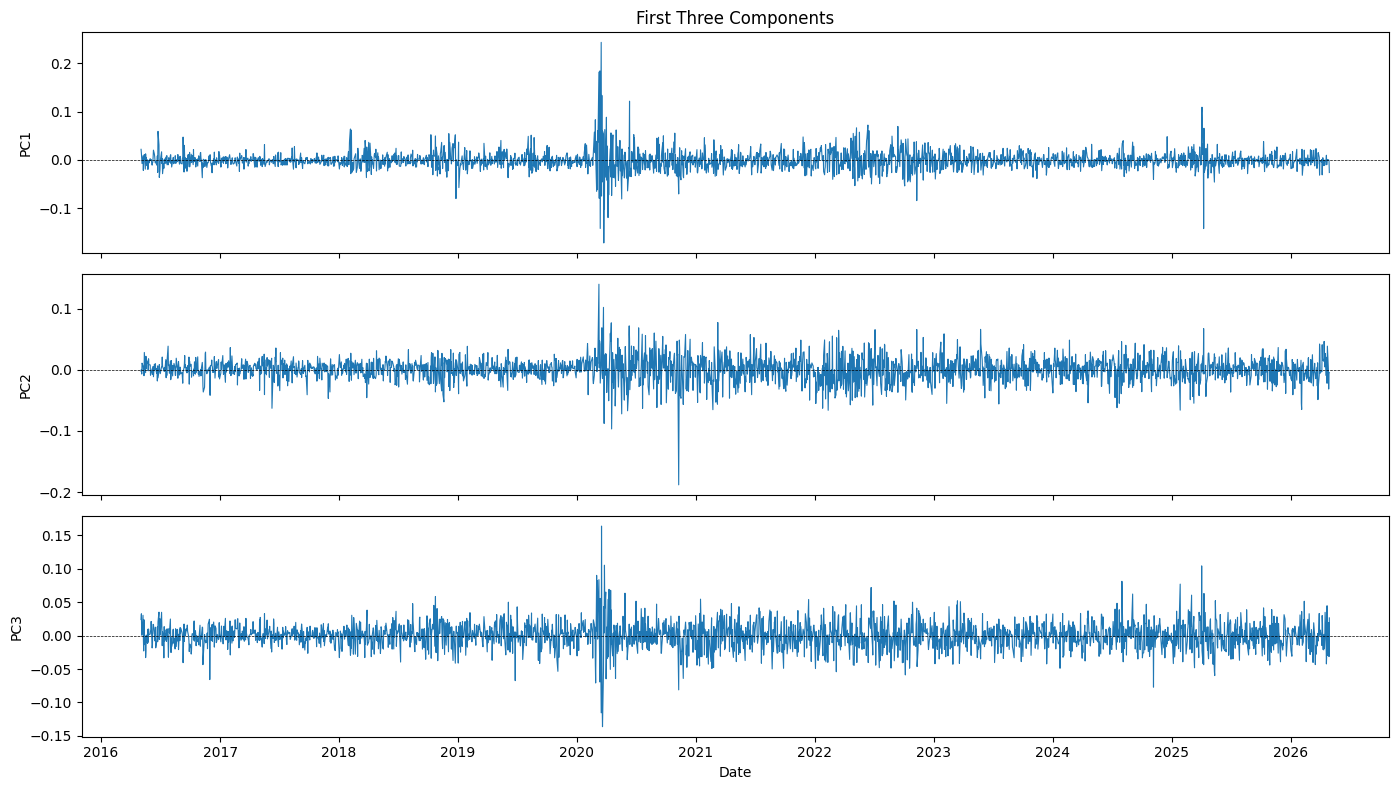

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

for i in range(3):
    axes[i].plot(dates, Vt[i], linewidth=0.8)
    axes[i].set_ylabel(f"PC{i+1}")
    axes[i].axhline(0, color="black", linewidth=0.5, linestyle="--")

axes[0].set_title("First Three Components")
axes[2].set_xlabel("Date")

plt.tight_layout()
plt.show()

We can clearly see that all three of the components seem to have sharp spikes around 2020 (COVID) which matches with what we would believe to be the dominant market factor. PC2 and PC3 capture cross sectional variation rather than the total market variation. However both PC2 and PC3 seem to have a big volatility in 2020 as well. PC1 seems to have increased variance during the 2022 Fed rate hike and also more volatility as we approach the modern day most likely from the tariffs and geopolitical tensions.

## Dimensionality Reduction: SVD vs t-SNE vs UMAP

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


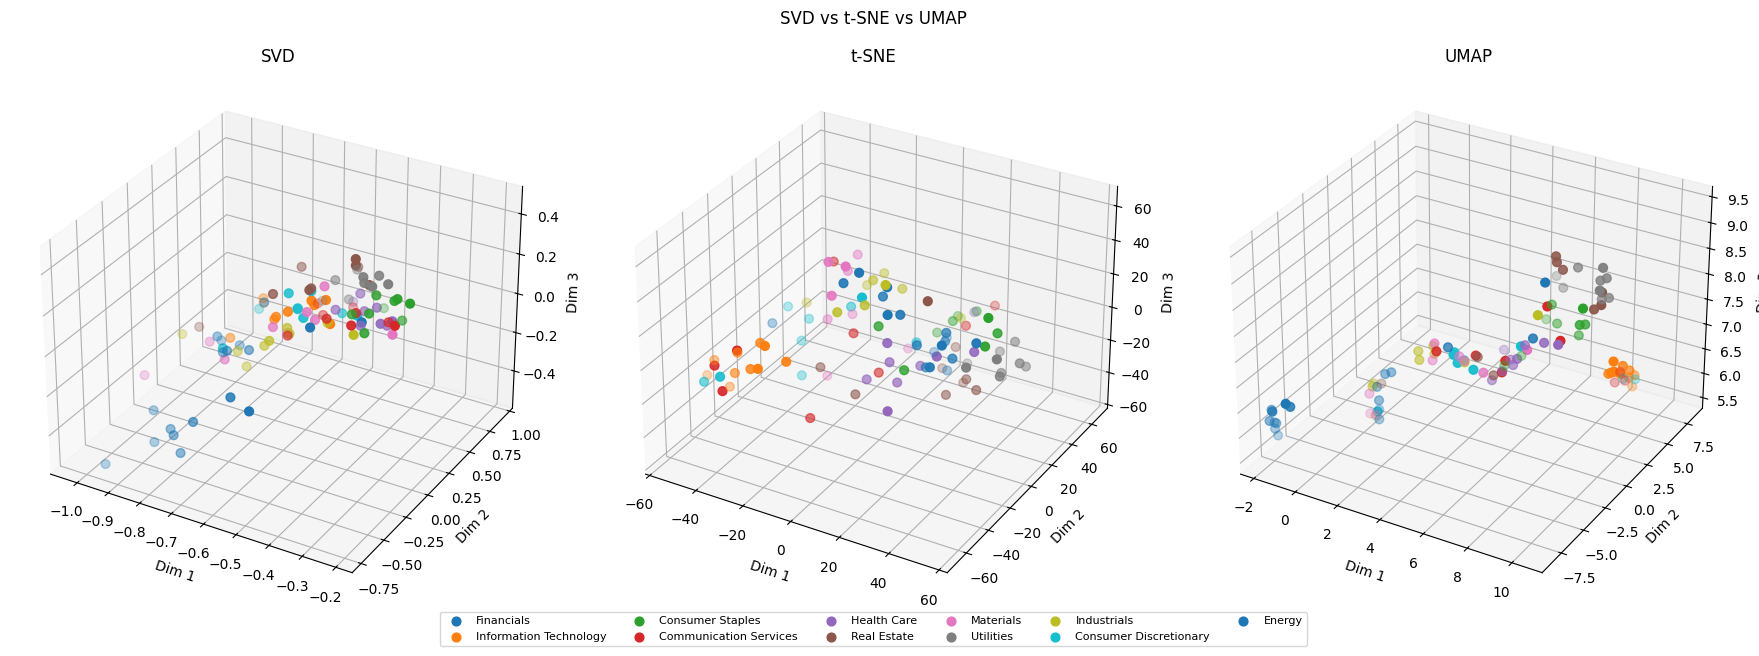

In [ ]:
from sklearn.manifold import TSNE
import umap

stock_projections = U[:, :3] * s[:3]

# t-SNE
tsne = TSNE(n_components=3, perplexity=10, random_state=42)
tsne_proj = tsne.fit_transform(stock_projections)

# UMAP
umap_model = umap.UMAP(n_components=3, n_neighbors=10, min_dist=0.2, random_state=42)
umap_proj = umap_model.fit_transform(stock_projections)

# Sector colors
unique_sectors = list(set(sectors_final))
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_sectors)))
sector_color_map = dict(zip(unique_sectors, colors))
point_colors = [sector_color_map[s] for s in sectors_final]

# Plot all three side by side
fig = plt.figure(figsize=(18, 6))

titles = ["SVD", "t-SNE", "UMAP"]
projections = [stock_projections, tsne_proj, umap_proj]

for i, (title, proj) in enumerate(zip(titles, projections)):
    ax = fig.add_subplot(1, 3, i+1, projection='3d')
    for sector in unique_sectors:
        idx = [j for j, s_name in enumerate(sectors_final) if s_name == sector]
        ax.scatter(
            proj[idx, 0],
            proj[idx, 1],
            proj[idx, 2],
            label=sector,
            s=40
        )
    ax.set_title(title)
    ax.set_xlabel("Dim 1")
    ax.set_ylabel("Dim 2")
    ax.set_zlabel("Dim 3")

handles, labels = fig.axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, fontsize=8, bbox_to_anchor=(0.5, -0.05))

plt.suptitle("SVD vs t-SNE vs UMAP", y=1.02)
plt.tight_layout()
plt.show()

The SVD projection shows there is some sector separation, utilities and energy seem to be very separated (opposite ends to each other) which is consistent with observations of the sectors. Many of the other sectors overlap a lot, which might show that the GICS doesn't fully determine the return movement and variation.

For T-SNE a perplexity of 10 was chosen since the sample size was relatively small and because in the original data around 9-10 stocks were in the same sector. For U-Map, a k of 10 and min_dist of 0.2 was chosen for a similar reason, keeping the neighborhood local. U-Map has an interesting tail like structure that forms that is different as well but still seems to separate the sectors. Both nonlinear embeddings show more cohesion within each sector than the SVD mapping but they all exhibit a lot of mixing. This shows that the overall market stock behavior seems to dominate over individual sectors for the most part.

## **Ethereum and Bitcoin Return Machine Learning Comparison**

This next part of the analysis will focus on cryptocurrency and trying to predict the difference in return between Ethereum and Bitcoin using different machine learning algorithms. 



First we will use yfinance to download the data and transform it and do the same transformations to make it question ready. We will also create the binary of whether or not BTC return is greater than ETH.

In [ ]:
btc = yf.download("BTC-USD", start="2016-05-01", end="2026-05-01", auto_adjust=True)["Close"].squeeze()
eth = yf.download("ETH-USD", start="2016-05-01", end="2026-05-01", auto_adjust=True)["Close"].squeeze()

crypto = pd.DataFrame({"BTC": btc, "ETH": eth}).dropna()

# Do the Log returns for the two
btc_ret = np.log(crypto["BTC"] / crypto["BTC"].shift(1))
eth_ret = np.log(crypto["ETH"] / crypto["ETH"].shift(1))

y = (btc_ret.shift(-1) > eth_ret.shift(-1)).astype(int)

feature_rows = []
for i in range(7, len(crypto) - 1):
    row = list(btc_ret.iloc[i-7:i]) + list(eth_ret.iloc[i-7:i])
    feature_rows.append(row)

feature_cols = [f"btc_lag{j}" for j in range(7, 0, -1)] + [f"eth_lag{j}" for j in range(7, 0, -1)]
X2 = pd.DataFrame(feature_rows, columns=feature_cols)
y2 = y.iloc[7:-1].reset_index(drop=True)

X2 = X2.dropna()
y2 = y2.loc[X2.index].reset_index(drop=True)
X2 = X2.reset_index(drop=True)


print(f"X2 shape: {X2.shape}")
print(f"y2 shape: {y2.shape}")


# Train, val, test
n = len(X2)
train_end = int(n * 0.60)
val_end   = int(n * 0.80)

X_train, y_train = X2.iloc[:train_end], y2.iloc[:train_end]
X_val,   y_val   = X2.iloc[train_end:val_end], y2.iloc[train_end:val_end]
X_test,  y_test  = X2.iloc[val_end:], y2.iloc[val_end:]


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


X2 shape: (3086, 14)
y2 shape: (3086,)


We will next check if the dataset is balanced or skewed for our assumption that it is balanced before training a logistic regression model. 

In [ ]:
for name, y_split in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    prop = y_split.mean()
    print(f"{name}: n={len(y_split)}, p={X2.shape[1]}, y=1 proportion={prop:.4f}, y=0 proportion={1-prop:.4f}")


Train: n=1851, p=14, y=1 proportion=0.5257, y=0 proportion=0.4743
Val: n=617, p=14, y=1 proportion=0.5559, y=0 proportion=0.4441
Test: n=618, p=14, y=1 proportion=0.5534, y=0 proportion=0.4466


The dataset is not imbalanced, the proportion of y=1 (cases where BTC outperforms ETH) is 52% in the train set, 55% in the validation set, and 55% in the test set. This seems stable over the splits which means no major distribution shift over time.

Now that our assumptions are good we will do the logistic regression and regularize the features using lasso regression. We wil iterate between the different hyperparameters until we get one that gives us the lowest validation error. 

Best C: 10.0 | Val error: 0.4376


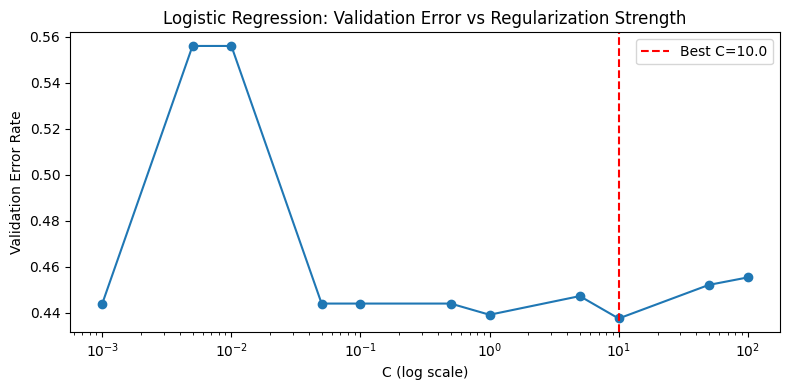

Train error: 0.4614 | Val error: 0.4376 | Test error: 0.4709


In [ ]:
from sklearn.linear_model import LogisticRegression

# This is for the regularization, values of c
C_values = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0]
val_errors = []

for C in C_values:
  model = LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, C=C, max_iter=1000, random_state=42)
  model.fit(X_train, y_train)
  val_err = 1 - model.score(X_val, y_val)
  val_errors.append(val_err)

best_C = C_values[np.argmin(val_errors)]
print(f"Best C: {best_C} | Val error: {min(val_errors):.4f}")

plt.figure(figsize=(8, 4))
plt.plot(C_values, val_errors, marker="o")
plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Validation Error Rate")
plt.title("Logistic Regression: Validation Error vs Regularization Strength")
plt.axvline(best_C, color="red", linestyle="--", label=f"Best C={best_C}")
plt.legend()
plt.tight_layout()
plt.show()

# Best C
lr_best = LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, C=best_C, max_iter=1000, random_state=42)
lr_best.fit(X_train, y_train)

lr_train_err = 1 - lr_best.score(X_train, y_train)
lr_val_err   = 1 - lr_best.score(X_val, y_val)
lr_test_err  = 1 - lr_best.score(X_test, y_test)

print(f"Train error: {lr_train_err:.4f} | Val error: {lr_val_err:.4f} | Test error: {lr_test_err:.4f}")

The best C from our scale was C = 10. The errors seem to be relatively similar where the Train error is 0.4614, Val error is 0.4376, and Test error is 0.4709.

Now we will train a boosting and bagging methods (random forest and XGBoost) in order to compare our logistic regression model with. 

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

rf_model = RandomForestClassifier(n_estimators=200, max_depth=2, random_state=42)
rf_model.fit(X_train, y_train)

rf_train_err = 1 - rf_model.score(X_train, y_train)
rf_val_err   = 1 - rf_model.score(X_val, y_val)
rf_test_err  = 1 - rf_model.score(X_test, y_test)

print(f"Random Forest: Train: {rf_train_err:.4f} | Val: {rf_val_err:.4f} | Test: {rf_test_err:.4f}")

xgb_model = XGBClassifier(n_estimators=200, max_depth=2, learning_rate=0.05, random_state=42, eval_metric="error", verbosity=0)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

xgb_train_err = 1 - xgb_model.score(X_train, y_train)
xgb_val_err   = 1 - xgb_model.score(X_val, y_val)
xgb_test_err  = 1 - xgb_model.score(X_test, y_test)

print(f"XGBoost: Train: {xgb_train_err:.4f} | Val: {xgb_val_err:.4f} | Test: {xgb_test_err:.4f}")

Random Forest: Train: 0.4144 | Val: 0.4441 | Test: 0.4547
XGBoost: Train: 0.3214 | Val: 0.4749 | Test: 0.4887


Both models seem to overfit, the training and test error are spread far apart. XGBoost seems to overfit more however, having a difference of 0.1673 between its training and test errors.

We will train a small neural network in Pytorch to compare against the other machine learning models. 

In [ ]:
import torch
import torch.nn as nn

X_train_t = torch.tensor(X_train.values, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
X_val_t   = torch.tensor(X_val.values, dtype=torch.float32)
y_val_t   = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1)
X_test_t  = torch.tensor(X_test.values, dtype=torch.float32)
y_test_t  = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

# Model as a class
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(14, 11)
        self.fc2 = nn.Linear(11, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.sigmoid(self.fc2(x))
        return x

model = Net()
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params}")

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.BCELoss()

best_val_loss = float("inf")
patience = 20
wait = 0
best_state = None

for epoch in range(500):
    model.train()
    optimizer.zero_grad()
    loss = criterion(model(X_train_t), y_train_t)
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(X_val_t), y_val_t).item()

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

model.load_state_dict(best_state)

# Get errors here
def error_rate(model, X, y):
    model.eval()
    with torch.no_grad():
        preds = (model(X) >= 0.5).float()
    return (preds != y).float().mean().item()

nn_train_err = error_rate(model, X_train_t, y_train_t)
nn_val_err   = error_rate(model, X_val_t, y_val_t)
nn_test_err  = error_rate(model, X_test_t, y_test_t)

print(f"Neural Net: Train: {nn_train_err:.4f} | Val: {nn_val_err:.4f} | Test: {nn_test_err:.4f}")

Total parameters: 177
Early stopping at epoch 185
Neural Net: Train: 0.4706 | Val: 0.4392 | Test: 0.4482


Now we compare the models:

In [ ]:
import pandas as pd
baseline_train = 1 - max(y_train.mean(), 1 - y_train.mean())
baseline_val   = 1 - max(y_val.mean(), 1 - y_val.mean())
baseline_test  = 1 - max(y_test.mean(), 1 - y_test.mean())


results = pd.DataFrame({
    "Model":      ["Naive Baseline", "Logistic Regression", "Random Forest", "XGBoost", "Neural Network"],
    "Train Error": [baseline_train, lr_train_err, rf_train_err, xgb_train_err, nn_train_err],
    "Val Error":   [baseline_val,   lr_val_err,   rf_val_err,   xgb_val_err,   nn_val_err],
    "Test Error":  [baseline_test,  lr_test_err,  rf_test_err,  xgb_test_err,  nn_test_err],
})

results = results.set_index("Model")
print(results.round(4).to_string())

                     Train Error  Val Error  Test Error
Model                                                  
Naive Baseline            0.4743     0.4441      0.4466
Logistic Regression       0.4614     0.4376      0.4709
Random Forest             0.4144     0.4441      0.4547
XGBoost                   0.3214     0.4749      0.4887
Neural Network            0.4706     0.4392      0.4482


It does not seem that any of the models outperforms the baseline. Random Forest and Neural Network come the closest with their test errors of 0.4547 and 0.4482 respectively. XGBoost seems to overfit the most with its training error the lowest but its test error being the highest. This makes XGBoost worse than doing nothing. This makes sense as the task of trying to predict returns from a 7 day return history doesn't seem like the best signal to test on.